<a href="https://colab.research.google.com/github/shiv6292/Logistic-Regression-AD3303/blob/main/LOGISTIC_REGRESSION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, classification_report
)

dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series((dataset.target == 0).astype(int), name="Malignant")

print(X.head())
print("Features shape:", X.shape)
print("Target counts (0=benign, 1=malignant):")
print(y.value_counts())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [ ]:
print("Data info:")
X.info()
display(X.describe())
print("Missing values per feature:\\n", X.isna().sum())
print("Duplicate rows:", X.duplicated().sum())

Data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness erro

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Missing values per feature:\n mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64
Duplicate rows: 0


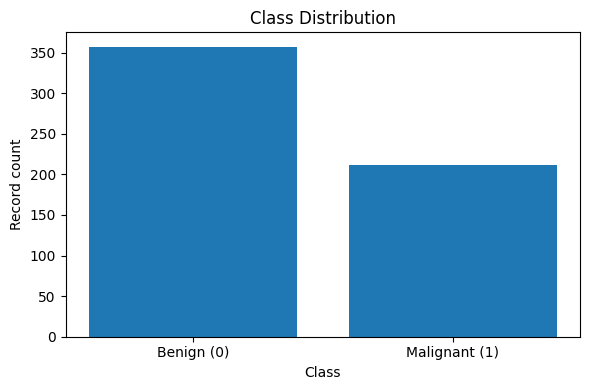

In [ ]:
counts = y.value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Benign (0)", "Malignant (1)"], counts.values)
plt.xlabel("Class")
plt.ylabel("Record count")
plt.title("Class Distribution")
plt.tight_layout()
plt.show()

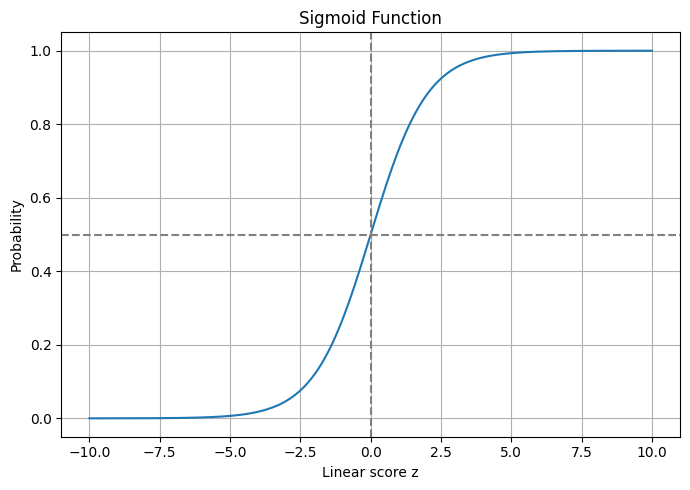

In [ ]:
z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))
plt.figure(figsize=(7, 5))
plt.plot(z, sigmoid)
plt.axhline(0.5, linestyle="--", color="gray")
plt.axvline(0, linestyle="--", color="gray")
plt.xlabel("Linear score z")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train size:", X_train.shape[0], "Test size:", X_test.shape[0])
print("Training class counts:\\n", y_train.value_counts())
print("Test class counts:\\n", y_test.value_counts())

Train size: 455 Test size: 114
Training class counts:\n Malignant
0    285
1    170
Name: count, dtype: int64
Test class counts:\n Malignant
0    72
1    42
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train_scaled, y_train)
print("Model trained successfully")
print("Intercept:", model.intercept_[0])

Model trained successfully
Intercept: -0.24300532690559115


In [ ]:
coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
}).sort_values("Coefficient", ascending=False)
display(coef_table)
print("Positive coefficient: higher feature value raises malignant log-odds, holding others fixed.")
print("Negative coefficient: higher feature value lowers malignant log-odds, holding others fixed.")

,Feature,Coefficient
21,worst texture,1.434093
10,radius error,1.233325
28,worst symmetry,1.061264
7,mean concave points,0.952813
26,worst concavity,0.911406
13,area error,0.909029
23,worst area,0.900477
20,worst radius,0.896968
6,mean concavity,0.782298
12,perimeter error,0.748295


Positive coefficient: higher feature value raises malignant log-odds, holding others fixed.
Negative coefficient: higher feature value lowers malignant log-odds, holding others fixed.


In [ ]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)
sample_results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Probability_Malignant": y_prob,
    "Predicted_At_0.5": y_pred
})
display(sample_results.head(10))

,Actual,Probability_Malignant,Predicted_At_0.5
0,0,0.000365,0
1,1,1.000000,1
2,0,0.042568,0
3,1,0.576187,1
4,0,0.509155,1
5,0,0.000616,0
6,1,0.761534,1
7,0,0.001012,0
8,0,0.000569,0
9,0,0.010768,0


Confusion matrix (rows=actual, columns=predicted): [[71  1]
 [ 3 39]]
TN=71, FP=1, FN=3, TP=39


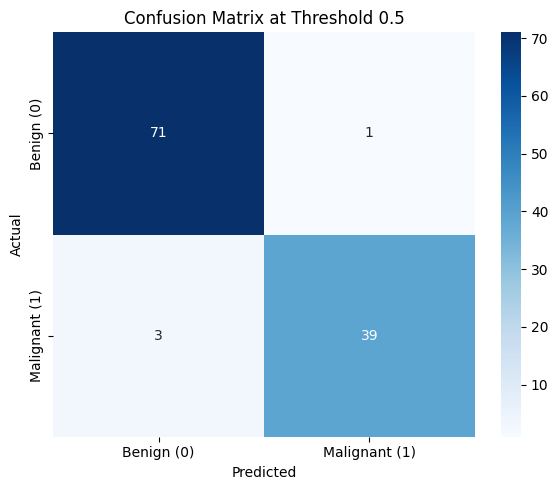

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix (rows=actual, columns=predicted):", cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign (0)", "Malignant (1)"],
            yticklabels=["Benign (0)", "Malignant (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix at Threshold 0.5")
plt.tight_layout()
plt.show()

In [ ]:
tn, fp, fn, tp = cm.ravel()
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall/Sensitivity": recall_score(y_test, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp) if (tn + fp) else 0,
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
display(pd.DataFrame({"Metric": metrics.keys(), "Value": metrics.values()}))
print(classification_report(y_test, y_pred, labels=[0, 1],
                          target_names=["Benign", "Malignant"], zero_division=0))

,Metric,Value
0,Accuracy,0.964912
1,Precision,0.975000
2,Recall/Sensitivity,0.928571
3,Specificity,0.986111
4,F1-score,0.951220
5,ROC-AUC,0.996032


              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [ ]:
majority_class = y_train.value_counts().idxmax()
baseline_pred = np.full(len(y_test), majority_class)
baseline_accuracy = accuracy_score(y_test, baseline_pred)
print("Majority class:", majority_class, "(0=benign, 1=malignant)")
print("Baseline accuracy:", baseline_accuracy)
print("Logistic Regression accuracy:", accuracy_score(y_test, y_pred))

Majority class: 0 (0=benign, 1=malignant)
Baseline accuracy: 0.631578947368421
Logistic Regression accuracy: 0.9649122807017544


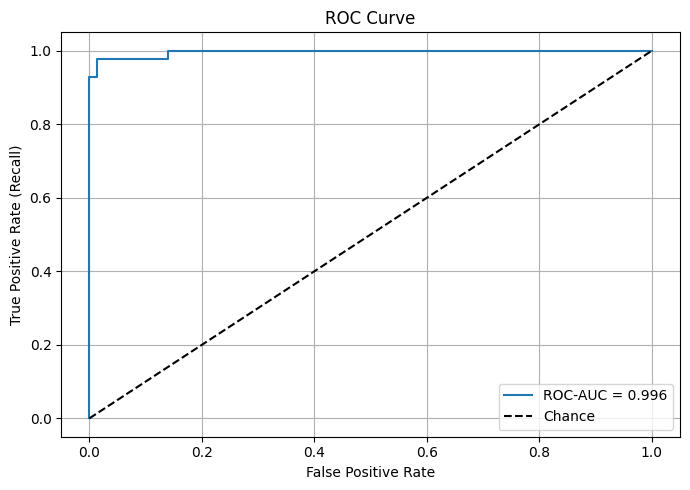

In [ ]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)
auc_value = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc_value:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
threshold_values = [0.3, 0.5, 0.7]
rows = []
for threshold in threshold_values:
    pred = (y_prob >= threshold).astype(int)
    cm_t = confusion_matrix(y_test, pred, labels=[0, 1])
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    rows.append({
        "Threshold": threshold,
        "Predicted Positive": int(pred.sum()),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Specificity": tn_t / (tn_t + fp_t) if (tn_t + fp_t) else 0,
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "TN": tn_t, "FP": fp_t, "FN": fn_t, "TP": tp_t
    })
threshold_table = pd.DataFrame(rows)
display(threshold_table)

,Threshold,Predicted Positive,Accuracy,Precision,Recall,Specificity,F1-score,TN,FP,FN,TP
0,0.3,42,0.982456,0.97619,0.976190,0.986111,0.97619,71,1,1,41
1,0.5,40,0.964912,0.97500,0.928571,0.986111,0.95122,71,1,3,39
2,0.7,38,0.964912,1.00000,0.904762,1.000000,0.95000,72,0,4,38


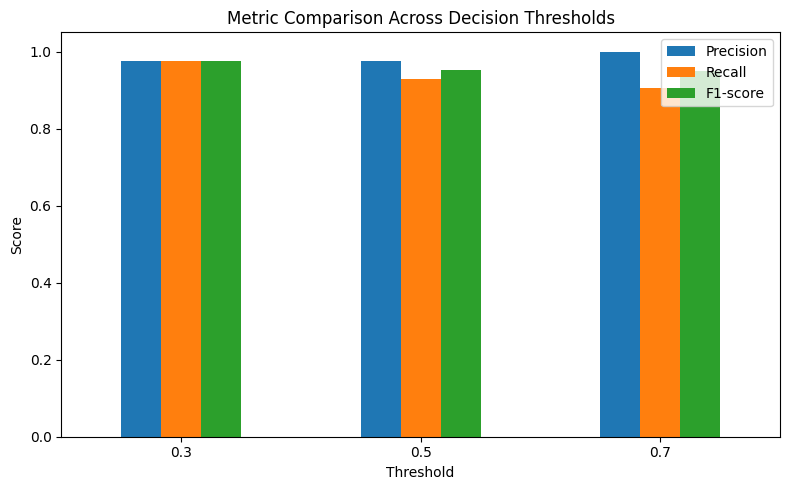

In [ ]:
threshold_table.set_index("Threshold")[["Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Metric Comparison Across Decision Thresholds")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

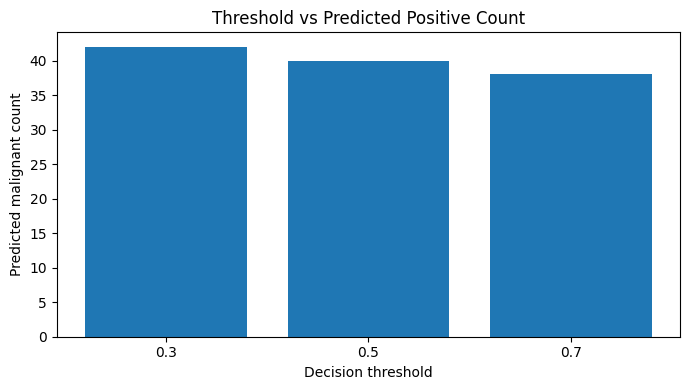

In [ ]:
plt.figure(figsize=(7, 4))
plt.bar(threshold_table["Threshold"].astype(str),
        threshold_table["Predicted Positive"])
plt.xlabel("Decision threshold")
plt.ylabel("Predicted malignant count")
plt.title("Threshold vs Predicted Positive Count")
plt.tight_layout()
plt.show()

In [ ]:
train_pred = model.predict(X_train_scaled)
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, y_pred)
print("Training accuracy:", train_accuracy)
print("Test accuracy:", test_accuracy)

Training accuracy: 0.9868131868131869
Test accuracy: 0.9649122807017544


In [ ]:
new_example = X_test.iloc[[0]]
new_example_scaled = scaler.transform(new_example)
new_probability = model.predict_proba(new_example_scaled)[0, 1]
new_label = int(new_probability >= 0.5)
print("Predicted probability of malignant:", new_probability)
print("Predicted class:", "Malignant (1)" if new_label == 1 else "Benign (0)")
print("Actual class of this example (for demonstration):", int(y_test.iloc[0]))

Predicted probability of malignant: 0.00036456811596278523
Predicted class: Benign (0)
Actual class of this example (for demonstration): 0
